# Pangaea Benchmark — Results Analysis
Load results from local experiment directories and build pivot tables.

In [1]:
import re
import os
from pathlib import Path
import pandas as pd
import numpy as np

EXPERIMENTS_BASE = Path("/dss/dsstbyfs02/pn49cu/pn49cu-dss-0001/niklas/experiments")

# ── Display name mappings ────────────────────────────────────────────────────
ENCODER_LABELS = {
    "carl_no_internal_norm":    "CARL",
    # carl_imagewise is CARL's recommended/default normalization variant -- it IS "CARL"
    # here. Plain dataset-wise "carl" is intentionally left unmapped (and excluded via
    # PANGAEA_ENCODER_ORDER below) so its rows don't collide with carl_imagewise's.
    "carl_imagewise":           "CARL",
    "dofa":                     "DOFA",
    "dofav2":                   "DOFA+",
    "panopticon":               "Panopticon",
    "copernicus_fm_base":       "Copernicus-FM",
    "smarties_vitb":            "SMARTIES",
    "dinov2_vitb14":            "DINOv2",
    "dinov3_vitl16_sat493m":    "DINOv3-ViT-L",
    "unet_encoder":             "UNet",
    "unet_encoder_mi":          "UNet",
    "vit_scratch":              "ViT-Scratch",
    "vit_scratch_mi":           "ViT-Scratch",
    "vit_scratch_p8":           "ViT-Scratch-p8",
    "vit_scratch_mi_p8":        "ViT-Scratch-p8",
    "universat":                "UniverSat",
}

DATASET_LABELS = {
    "hlsburnscars":      "HLS-BurnScars",
    "sen1floods11":      "Sen1Floods11",
    "mados":             "MADOS",
    "pastis":            "PASTIS",
    "dynamicen":         "DynamicEarthNet",
    # CropTypeMapping intentionally excluded -- too seed-dependent (see the
    # 3-seed ablation: some encoders swing >20 mIoU points across seeds) to
    # be meaningful in a single-run comparison table.
    "spacenet7cd":       "SpaceNet7-CD",
    "ai4smallfarms":     "AI4SmallFarms",
    "fivebillionpixels": "FiveBillionPixels",
}

DATASET_ORDER = list(DATASET_LABELS.keys())

# Encoders listed in longest-first order for greedy name matching.
# carl_imagewise MUST appear before carl to avoid carl matching carl_imagewise_*.
KNOWN_ENCODERS = [
    "copernicus_fm_base", "copernicus_fm_large",
    "carl_no_internal_norm",
    "carl_imagewise",
    "dinov3_vitl16_sat493m",
    "smarties_vitb", "dinov2_vitb14",
    "dofav2", "dofa", "panopticon", "carl",
    "vit_scratch_mi_p8", "vit_scratch_p8",
    "vit_scratch_mi", "vit_scratch",
    "unet_encoder_mi", "unet_encoder",
    "universat",
]

# Canonical row order for the main Pangaea (full-band) tables. Passing this as
# `encoder_order` to to_pivot() both orders the rows and drops anything not
# listed here -- e.g. plain dataset-wise "carl" (superseded by carl_imagewise,
# which is now labeled "CARL") and stray/blank rows from encoders this
# notebook doesn't track (e.g. UniverSat).
PANGAEA_ENCODER_ORDER = [
    "DOFA", "DOFA+", "Copernicus-FM", "Panopticon", "CARL", "SMARTIES",
    "DINOv2", "DINOv3-ViT-L", "ViT-Frozen-p16", "ViT-Frozen-p8", "ViT-Scratch", "UNet",
]

KNOWN_DECODERS = [
    "seg_upernet_mt_ltae", "seg_upernet",
    "seg_siamupernet_conc", "seg_siamupernet_diff",
    "seg_siam_mlp_fusion", "seg_mlp_fusion",
    "seg_siamunet_conc", "seg_siamunet_diff", "seg_unet",
    "seg_linear_probe", "seg_siam_linear_probe",
    "cls_linear", "cls_linear_probe",
]

DATASET_RE = re.compile(
    r"_(" + "|".join(re.escape(d) for d in DATASET_ORDER) + r")_"
)

print("Config loaded.")

Config loaded.


In [2]:
# ── Core parsing functions ───────────────────────────────────────────────────

def parse_run_dir_name(name: str) -> dict:
    """Extract dataset, encoder, decoder from a run directory name."""
    m = DATASET_RE.search(name)
    if not m:
        return {}
    dataset = m.group(1)
    rest = name[m.end():]

    # Ablation/variant tags inserted between dataset and encoder (e.g. the
    # DynamicEarthNet true-wavelength B8A rerun uses "..._true_wl_<encoder>_...")
    # must be stripped before encoder matching, or encoder detection silently
    # fails and the run gets dropped into a blank-encoder row.
    for tag in ("true_wl_",):
        if rest.startswith(tag):
            rest = rest[len(tag):]
            break

    encoder = next((e for e in KNOWN_ENCODERS if rest.startswith(e + "_")), None)
    if encoder:
        rest = rest[len(encoder) + 1:]

    decoder = next((d for d in KNOWN_DECODERS if rest.startswith(d)), None)

    return {"dataset": dataset, "encoder": encoder or "", "decoder": decoder or ""}


def parse_log_metrics(log_path: Path) -> dict:
    """
    Parse train.log-0 for test metrics.

    Extracts the Mean values from [test] IoU, F1, Precision, Recall sections.
    Returns a dict with keys: test_mIoU, test_mF1, test_mPrecision, test_mRecall.
    For change detection (IoU section contains exactly 2 classes), also returns test_IoU.
    """
    if not log_path.exists():
        return {}

    text = log_path.read_text(errors="ignore")

    # Find all [test] sections — there may be multiple if val was run at test time
    # We want the LAST occurrence (final test run)
    sections = re.split(r"\[test\] ------- IoU", text)
    if len(sections) < 2:
        return {}
    test_block = "[test] ------- IoU" + sections[-1]

    metrics = {}
    metric_map = {
        "IoU":       "test_mIoU",
        "F1-score":  "test_mF1",
        "Precision": "test_mPrecision",
        "Recall":    "test_mRecall",
    }

    for section_name, metric_key in metric_map.items():
        # Find the Mean line inside this section
        pattern = rf"\[test\] ------- {section_name}.*?\[test\] Mean\s+([\d.]+)"
        m = re.search(pattern, test_block, re.DOTALL)
        if m:
            metrics[metric_key] = float(m.group(1))

    return metrics


def load_experiment_folder(
    folder: str | Path,
    encoder_map: dict | None = None,
    dataset_map: dict | None = None,
    metric: str = "test_mIoU",
    keep_all_metrics: bool = False,
) -> pd.DataFrame:
    """
    Load all runs from an experiment folder and return a long-form DataFrame.

    Parameters
    ----------
    folder : path to an experiment directory (e.g. pangaea_full_seg/upernet/panopticon_seg)
             OR a parent directory containing multiple encoder subdirectories.
             The function auto-detects whether run dirs are direct children or
             one level deeper.
    encoder_map : optional override for encoder display names {raw: display}
    dataset_map : optional override for dataset display names {raw: display}
    metric : which metric column to extract (default: test_mIoU)
    keep_all_metrics : if True, keep all parsed metrics instead of just `metric`

    Returns
    -------
    Long-form DataFrame with columns: run_dir, encoder, decoder, dataset, [metrics...]
    """
    enc_map = {**ENCODER_LABELS, **(encoder_map or {})}
    ds_map  = {**DATASET_LABELS,  **(dataset_map  or {})}
    folder  = Path(folder)

    # Collect candidate run directories:
    # A run dir contains train.log-0. Walk up to 2 levels deep.
    run_dirs = []
    for child in sorted(folder.iterdir()):
        if not child.is_dir():
            continue
        if (child / "train.log-0").exists():
            run_dirs.append(child)
        else:
            for grandchild in sorted(child.iterdir()):
                if grandchild.is_dir() and (grandchild / "train.log-0").exists():
                    run_dirs.append(grandchild)

    rows = []
    for run_dir in run_dirs:
        parsed = parse_run_dir_name(run_dir.name)
        if not parsed.get("dataset"):
            continue
        log_metrics = parse_log_metrics(run_dir / "train.log-0")
        if not log_metrics:
            continue

        enc_raw = parsed["encoder"]
        ds_raw  = parsed["dataset"]

        row = {
            "run_dir": run_dir.name,
            "encoder_raw": enc_raw,
            "decoder":     parsed["decoder"],
            "dataset_raw": ds_raw,
            "encoder":     enc_map.get(enc_raw, enc_raw),
            "dataset":     ds_map.get(ds_raw, ds_raw),
        }
        if keep_all_metrics:
            row.update(log_metrics)
        elif metric in log_metrics:
            row[metric] = log_metrics[metric]
        else:
            continue
        rows.append(row)

    return pd.DataFrame(rows)


def to_pivot(
    df: pd.DataFrame,
    metric: str = "test_mIoU",
    index: str = "encoder",
    columns: str = "dataset",
    aggfunc: str = "last",  # latest (chronologically last) run wins on duplicate encoder x dataset cells
    dataset_order: list | None = None,
    encoder_order: list | None = None,
    add_mean: bool = True,
    add_avg_rank: bool = True,
) -> pd.DataFrame:
    """
    Pivot a long-form results DataFrame to encoder × dataset.

    Parameters
    ----------
    df           : output of load_experiment_folder() or load_geobench_seg_folder()
    metric       : value column to pivot
    index        : row grouping (default: encoder display name)
    columns      : column grouping (default: dataset display name)
    aggfunc      : how to aggregate duplicates — 'max', 'mean', or 'last'
    dataset_order: explicit column order; defaults to DATASET_LABELS order
    encoder_order: explicit row order
    add_mean     : whether to append a Mean column (mean mIoU over available tasks)
    add_avg_rank : whether to append an Avg Rank column (mean per-task rank,
                   rank 1 = best; lower is better; NaN tasks are skipped)
    """
    if metric not in df.columns:
        raise ValueError(f"Metric '{metric}' not in DataFrame columns: {list(df.columns)}")

    pivot = df.pivot_table(
        index=index, columns=columns, values=metric,
        aggfunc=aggfunc
    )

    # Apply column order
    if dataset_order is None:
        ordered_ds = [DATASET_LABELS[d] for d in DATASET_ORDER if DATASET_LABELS[d] in pivot.columns]
        remaining  = [c for c in pivot.columns if c not in ordered_ds]
        dataset_order = ordered_ds + remaining
    pivot = pivot.reindex(columns=[c for c in dataset_order if c in pivot.columns])

    # Apply row order
    if encoder_order is not None:
        pivot = pivot.reindex([e for e in encoder_order if e in pivot.index])

    # Avg Rank: rank encoders within each dataset (1 = best), then average across tasks
    if add_avg_rank:
        data_cols = list(pivot.columns)
        ranks = pivot[data_cols].rank(axis=0, ascending=False, method="average", na_option="keep")
        pivot["Avg Rank"] = ranks.mean(axis=1, skipna=True).round(2)

    if add_mean:
        data_cols = [c for c in pivot.columns if c not in ("Mean", "Avg Rank")]
        pivot.insert(len(pivot.columns) - (1 if add_avg_rank else 0),
                     "Mean",
                     pivot[data_cols].mean(axis=1, skipna=True).round(3))

    return pivot.round(2)


print("Functions defined: load_experiment_folder(), to_pivot()")

Functions defined: load_experiment_folder(), to_pivot()


## Full-band UPerNet results

In [3]:
_VIT_FROZEN_MAP = {
    "vit_scratch":       "ViT-Frozen-p16",
    "vit_scratch_mi":    "ViT-Frozen-p16",
    "vit_scratch_p8":    "ViT-Frozen-p8",
    "vit_scratch_mi_p8": "ViT-Frozen-p8",
}

upernet_path = EXPERIMENTS_BASE / "pangaea_full_seg" / "upernet"
_dfs = []
for sf in sorted(upernet_path.iterdir()):
    if not sf.is_dir():
        continue
    enc_map = _VIT_FROZEN_MAP if "frozen" in sf.name else None
    _dfs.append(load_experiment_folder(sf, encoder_map=enc_map, metric="test_mIoU"))

df_upernet = pd.concat(_dfs, ignore_index=True)
print(f"{len(df_upernet)} runs loaded")
df_upernet.groupby(["encoder", "dataset"])["test_mIoU"].max().unstack()

135 runs loaded


dataset,AI4SmallFarms,DynamicEarthNet,FiveBillionPixels,HLS-BurnScars,MADOS,PASTIS,Sen1Floods11,SpaceNet7-CD
encoder,,,,,,,,
CARL,31.655,37.749,50.323,83.943,46.630,39.502,89.023,58.860
Copernicus-FM,33.346,37.715,62.801,82.332,56.897,33.785,89.110,62.360
DINOv2,35.205,26.583,64.580,74.482,58.777,18.777,70.020,62.919
DINOv3-ViT-L,37.396,39.041,74.209,79.752,67.179,26.834,72.718,63.802
DOFA,36.435,41.124,69.929,80.644,60.389,30.373,87.692,62.119
DOFA+,38.084,43.906,71.216,78.274,48.602,19.792,88.008,63.634
Panopticon,37.883,44.738,70.096,84.225,68.217,36.814,90.591,63.482
SMARTIES,35.465,40.666,57.318,82.845,62.282,35.750,90.052,59.508
UNet,46.337,39.473,65.588,85.486,53.668,26.843,91.038,62.058


In [4]:
pivot_upernet = to_pivot(df_upernet, encoder_order=PANGAEA_ENCODER_ORDER)
pivot_upernet

dataset,HLS-BurnScars,Sen1Floods11,MADOS,PASTIS,DynamicEarthNet,SpaceNet7-CD,AI4SmallFarms,FiveBillionPixels,Mean,Avg Rank
encoder,,,,,,,,,,
DOFA,80.64,87.69,60.39,30.37,39.59,62.12,36.44,69.93,58.40,5.50
DOFA+,78.27,88.01,48.60,19.79,43.91,63.45,38.08,71.22,56.42,5.50
Copernicus-FM,82.33,89.11,56.90,33.78,36.47,61.95,33.35,62.80,57.09,6.25
Panopticon,84.22,90.59,68.22,36.81,44.74,63.48,37.88,70.10,62.01,1.88
CARL,83.94,89.02,46.63,39.50,37.75,58.86,31.66,50.32,54.71,7.38
SMARTIES,82.84,90.05,62.28,35.75,40.67,58.85,35.47,57.32,57.90,5.12
DINOv2,74.48,70.02,58.78,18.78,26.58,62.92,35.20,64.58,51.42,8.50
DINOv3-ViT-L,79.75,72.72,67.18,26.83,39.04,63.38,37.40,74.21,57.56,5.38
ViT-Frozen-p16,80.84,88.08,44.23,6.54,31.56,58.66,32.62,48.34,48.86,10.12


## Full-band MLP Fusion results

In [5]:
mlp_path = EXPERIMENTS_BASE / "pangaea_full_seg" / "mlp_fusion"
_dfs = []
for sf in sorted(mlp_path.iterdir()):
    if not sf.is_dir():
        continue
    enc_map = _VIT_FROZEN_MAP if "frozen" in sf.name else None
    _dfs.append(load_experiment_folder(sf, encoder_map=enc_map, metric="test_mIoU"))

df_mlp = pd.concat(_dfs, ignore_index=True)

# UNet has no MLPFusionDecoder variant -- it only ever uses its own native
# seg_unet decoder. Per request, its UPerNet-track (native-decoder) numbers
# are carried into this table as a reference row rather than left blank;
# this is flagged in the thesis prose, not implied to be a real MLP-Fusion run.
df_mlp = pd.concat([df_mlp, df_upernet[df_upernet["encoder"] == "UNet"]], ignore_index=True)

print(f"{len(df_mlp)} runs loaded (incl. UNet native-decoder reference rows)")
pivot_mlp = to_pivot(df_mlp, encoder_order=PANGAEA_ENCODER_ORDER)
pivot_mlp

128 runs loaded (incl. UNet native-decoder reference rows)


dataset,HLS-BurnScars,Sen1Floods11,MADOS,PASTIS,DynamicEarthNet,SpaceNet7-CD,AI4SmallFarms,FiveBillionPixels,Mean,Avg Rank
encoder,,,,,,,,,,
DOFA,81.40,84.84,52.93,24.45,39.43,59.04,35.49,66.90,55.56,5.25
DOFA+,74.84,84.24,44.31,19.78,39.48,60.17,35.15,66.86,53.10,6.50
Copernicus-FM,80.74,85.05,49.66,29.85,36.04,59.16,34.68,59.12,54.29,6.12
Panopticon,83.38,85.88,66.75,34.48,42.57,60.12,34.41,66.22,59.23,3.00
CARL,79.08,86.85,45.21,36.87,37.17,57.49,30.42,46.00,52.39,7.12
SMARTIES,81.47,85.26,55.42,33.76,33.51,57.62,33.82,51.77,54.08,6.38
DINOv2,74.10,68.18,57.28,13.94,23.51,59.73,34.20,62.35,49.16,8.50
DINOv3-ViT-L,78.83,73.29,70.47,22.45,38.58,59.33,35.38,70.20,56.07,5.62
ViT-Frozen-p16,79.83,84.65,32.96,26.58,33.47,57.14,32.40,41.88,48.62,9.75


## RGB UPerNet results

In [6]:
df_rgb_up = load_experiment_folder(
    EXPERIMENTS_BASE / "pangaea_rgb" / "upernet",
    metric="test_mIoU",
)

# DINOv2 and DINOv3 are RGB-only — pull their results from the full-seg folder
_dinov2_up = load_experiment_folder(
    EXPERIMENTS_BASE / "pangaea_full_seg" / "upernet" / "dinov2_seg",
    metric="test_mIoU",
)
_dinov3_up = load_experiment_folder(
    EXPERIMENTS_BASE / "pangaea_full_seg" / "upernet" / "dinov3_vitl_seg",
    metric="test_mIoU",
)
df_rgb_up = pd.concat([df_rgb_up, _dinov2_up, _dinov3_up], ignore_index=True)

print(f"{len(df_rgb_up)} runs loaded")
pivot_rgb_up = to_pivot(df_rgb_up)
pivot_rgb_up.drop(columns=["SpaceNet7-CD"], inplace=True)
pivot_rgb_up

85 runs loaded


dataset,HLS-BurnScars,Sen1Floods11,MADOS,PASTIS,DynamicEarthNet,AI4SmallFarms,FiveBillionPixels,Mean,Avg Rank
encoder,,,,,,,,,
CARL,69.78,65.79,37.86,26.11,30.57,31.37,42.74,43.46,7.71
Copernicus-FM,75.64,74.42,65.11,23.59,37.06,35.11,67.70,54.09,4.29
DINOv2,74.48,70.02,58.78,18.78,26.58,35.20,64.58,51.42,6.00
DINOv3-ViT-L,79.75,72.72,67.18,26.83,39.04,37.40,74.21,57.56,1.88
DOFA,76.04,76.66,65.59,23.80,39.61,35.51,69.82,55.29,2.43
DOFA+,78.35,75.28,60.86,22.70,34.57,38.75,72.47,54.71,3.29
Panopticon,75.05,76.62,59.25,28.15,35.59,35.38,68.08,54.02,3.57
SMARTIES,71.71,68.51,40.07,21.48,28.73,32.62,50.38,44.78,7.29
ViT-Scratch,71.22,60.77,33.85,8.00,33.53,29.06,57.81,42.03,8.43


## RGB MLP Fusion results

In [7]:
df_rgb_mlp = load_experiment_folder(
    EXPERIMENTS_BASE / "pangaea_rgb" / "mlp_fusion",
    metric="test_mIoU",
)

# DINOv2 and DINOv3 are RGB-only — pull their results from the full-seg folder
_dinov2_mlp = load_experiment_folder(
    EXPERIMENTS_BASE / "pangaea_full_seg" / "mlp_fusion" / "dinov2_mlp_fusion",
    metric="test_mIoU",
)
_dinov3_mlp = load_experiment_folder(
    EXPERIMENTS_BASE / "pangaea_full_seg" / "mlp_fusion" / "dinov3_vitl_mlp_fusion",
    metric="test_mIoU",
)
df_rgb_mlp = pd.concat([df_rgb_mlp, _dinov2_mlp, _dinov3_mlp], ignore_index=True)

print(f"{len(df_rgb_mlp)} runs loaded")
pivot_rgb_mlp = to_pivot(df_rgb_mlp)
pivot_rgb_mlp.drop(columns=["SpaceNet7-CD"], inplace=True)
pivot_rgb_mlp

78 runs loaded


dataset,HLS-BurnScars,Sen1Floods11,MADOS,PASTIS,DynamicEarthNet,AI4SmallFarms,FiveBillionPixels,Mean,Avg Rank
encoder,,,,,,,,,
CARL,70.38,63.56,34.48,23.32,27.34,27.47,37.30,40.55,7.14
Copernicus-FM,75.78,72.62,59.23,22.18,30.81,35.21,64.24,51.44,3.86
DINOv2,74.10,68.18,57.28,13.94,23.51,34.20,62.35,49.16,6.00
DINOv3-ViT-L,78.83,73.29,70.47,22.45,38.58,35.38,70.20,56.07,1.62
DOFA,74.79,73.56,57.42,22.28,34.98,34.77,66.84,52.09,3.57
DOFA+,76.29,72.51,53.05,21.65,33.17,34.95,67.21,51.26,4.00
Panopticon,75.49,74.99,61.62,26.60,33.50,34.85,64.78,53.12,2.71
SMARTIES,71.56,67.62,37.82,18.40,25.68,31.02,44.00,42.30,7.14
ViT-Scratch,68.32,55.19,25.29,NaN,23.81,30.78,32.32,39.29,9.67


## Advanced usage examples

In [8]:
# Load a single encoder folder
df_panopticon = load_experiment_folder(
    EXPERIMENTS_BASE / "pangaea_full_seg" / "upernet" / "panopticon_seg",
    keep_all_metrics=True,  # get mIoU, mF1, Precision, Recall
)
df_panopticon[["dataset", "test_mIoU", "test_mF1", "test_mPrecision", "test_mRecall"]]

,dataset,test_mIoU,test_mF1,test_mPrecision,test_mRecall
0,DynamicEarthNet,40.553,51.097,51.891,54.459
1,PASTIS,36.814,50.169,46.795,58.957
2,FiveBillionPixels,70.096,80.318,79.304,82.316
3,MADOS,68.217,78.297,78.187,80.500
4,Sen1Floods11,90.591,94.924,94.257,95.619
5,HLS-BurnScars,84.225,90.937,90.860,91.013
6,AI4SmallFarms,37.883,53.821,58.305,56.179
7,SpaceNet7-CD,60.769,68.017,72.581,65.009
8,DynamicEarthNet,44.738,56.166,56.255,58.214
9,SpaceNet7-CD,63.482,71.471,77.407,67.674


In [9]:
# Compare UPerNet vs MLP fusion side-by-side for full-band runs
mean_up  = to_pivot(df_upernet, encoder_order=PANGAEA_ENCODER_ORDER)[["Mean"]].rename(columns={"Mean": "UPerNet"})
mean_mlp = to_pivot(df_mlp, encoder_order=PANGAEA_ENCODER_ORDER)[["Mean"]].rename(columns={"Mean": "MLP Fusion"})
comparison = mean_up.join(mean_mlp, how="outer")
comparison["Δ (UPerNet - MLP)"] = (comparison["UPerNet"] - comparison["MLP Fusion"]).round(2)
comparison.reindex([e for e in PANGAEA_ENCODER_ORDER if e in comparison.index])

dataset,UPerNet,MLP Fusion,Δ (UPerNet - MLP)
encoder,,,
DOFA,58.40,55.56,2.84
DOFA+,56.42,53.10,3.32
Copernicus-FM,57.09,54.29,2.80
Panopticon,62.01,59.23,2.78
CARL,54.71,52.39,2.32
SMARTIES,57.90,54.08,3.82
DINOv2,51.42,49.16,2.26
DINOv3-ViT-L,57.56,56.07,1.49
ViT-Frozen-p16,48.86,48.62,0.24


## GeoBench Segmentation results

In [10]:
# ── GeoBench-specific constants ──────────────────────────────────────────────

GEOBENCH_SEG_DATASET_LABELS = {
    "mcashew-plantation":    "Cashew-Plant",
    "mchesapeake-landcover": "Chesapeake",
    "mneontree":             "NeonTree",
    "mnz-cattle":            "NZ-Cattle",
    "mpv4ger-seg":           "PV4Ger-Seg",
    "msa-crop-type":         "SA-Crop-Type",
}
GEOBENCH_SEG_DATASET_ORDER = list(GEOBENCH_SEG_DATASET_LABELS.keys())

GEOBENCH_DATASET_RE = re.compile(
    r"_(" + "|".join(re.escape(d) for d in GEOBENCH_SEG_DATASET_ORDER) + r")_"
)

# Keyed by experiment subfolder name so vit_frozen_p16 and vit_scratch are distinct
# even though both use the vit_scratch encoder config inside their run dirs.
GEOBENCH_FOLDER_ENCODER_LABELS = {
    "dofa":               "DOFA",
    "dofav2":             "DOFA+",
    # carl_imagewise is CARL's standard/default variant here too, same as the
    # main Pangaea tables -- plain dataset-wise "carl" is left unmapped and
    # excluded via GEOBENCH_ENCODER_ORDER below.
    "carl_imagewise":     "CARL",
    "panopticon":         "Panopticon",
    "smarties_vitb":      "SMARTIES",
    "copernicus_fm_base": "Copernicus-FM",
    "dinov2":             "DINOv2",
    "dinov3_vitl":        "DINOv3-ViT-L",
    "unet":               "UNet",
    "vit_scratch":        "ViT-Scratch",
    "vit_frozen_p16":     "ViT-Frozen-p16",
    "vit_frozen_p8":      "ViT-Frozen-p8",
}

# Same relative ordering as PANGAEA_ENCODER_ORDER.
GEOBENCH_ENCODER_ORDER = [
    "DOFA", "DOFA+", "Copernicus-FM", "Panopticon", "CARL", "SMARTIES",
    "DINOv2", "DINOv3-ViT-L", "ViT-Frozen-p16", "ViT-Frozen-p8", "ViT-Scratch", "UNet",
]

GEOBENCH_DATASET_DISPLAY_ORDER = [
    GEOBENCH_SEG_DATASET_LABELS[d] for d in GEOBENCH_SEG_DATASET_ORDER
]


def load_geobench_seg_folder(base_path, metric="test_mIoU"):
    """
    Load GeoBench seg results from base_path/<enc_folder>/<run_dir>/train.log-0.

    Uses the subfolder name (enc_folder) for the encoder display label so that
    vit_frozen_p16 and vit_scratch are distinguished even though both contain
    runs with the same vit_scratch encoder config string in their directory names.
    """
    rows = []
    for enc_folder in sorted(Path(base_path).iterdir()):
        if not enc_folder.is_dir():
            continue
        enc_label = GEOBENCH_FOLDER_ENCODER_LABELS.get(enc_folder.name, enc_folder.name)

        for run_dir in sorted(enc_folder.iterdir()):
            if not run_dir.is_dir():
                continue
            m = GEOBENCH_DATASET_RE.search(run_dir.name)
            if not m:
                continue
            ds_raw = m.group(1)
            log_metrics = parse_log_metrics(run_dir / "train.log-0")
            if metric not in log_metrics:
                continue
            rows.append({
                "encoder":     enc_label,
                "dataset":     GEOBENCH_SEG_DATASET_LABELS.get(ds_raw, ds_raw),
                "dataset_raw": ds_raw,
                metric:        log_metrics[metric],
            })
    return pd.DataFrame(rows)


print("GeoBench constants and load_geobench_seg_folder() defined.")

GeoBench constants and load_geobench_seg_folder() defined.


In [11]:
# GeoBench — UPerNet
df_geo_up = load_geobench_seg_folder(
    EXPERIMENTS_BASE / "geobench" / "seg" / "UPerNet",
    metric="test_mIoU",
)
print(f"{len(df_geo_up)} runs loaded")

pivot_geo_up = to_pivot(
    df_geo_up,
    metric="test_mIoU",
    dataset_order=GEOBENCH_DATASET_DISPLAY_ORDER,
    encoder_order=GEOBENCH_ENCODER_ORDER,
)
pivot_geo_up

78 runs loaded


dataset,Cashew-Plant,Chesapeake,NeonTree,NZ-Cattle,PV4Ger-Seg,SA-Crop-Type,Mean,Avg Rank
encoder,,,,,,,,
DOFA,66.90,59.63,58.67,84.36,94.93,32.44,66.16,5.67
DOFA+,65.20,61.00,61.56,84.89,95.50,29.78,66.32,5.00
Copernicus-FM,69.90,66.52,56.52,84.07,95.09,34.04,67.69,4.50
Panopticon,73.17,60.11,55.58,84.14,94.19,36.21,67.23,4.67
CARL,64.89,51.85,54.18,81.08,88.11,33.04,62.19,10.33
SMARTIES,71.06,61.22,54.39,82.48,91.54,32.70,65.56,7.33
DINOv2,66.30,58.07,55.56,84.55,93.80,30.43,64.78,7.50
DINOv3-ViT-L,74.31,64.32,59.89,84.57,95.12,35.21,68.90,2.50
ViT-Frozen-p16,62.69,54.26,53.20,82.08,89.71,30.48,62.07,10.83


In [12]:
# GeoBench — MLP Fusion
df_geo_mlp = load_geobench_seg_folder(
    EXPERIMENTS_BASE / "geobench" / "seg" / "MLPFusion",
    metric="test_mIoU",
)

# UNet has no MLPFusionDecoder variant here either -- carry its UPerNet
# (native seg_unet decoder) rows in as a reference, same treatment as the
# main Pangaea MLP-Fusion table.
df_geo_mlp = pd.concat([df_geo_mlp, df_geo_up[df_geo_up["encoder"] == "UNet"]], ignore_index=True)

print(f"{len(df_geo_mlp)} runs loaded (incl. UNet native-decoder reference rows)")

pivot_geo_mlp = to_pivot(
    df_geo_mlp,
    metric="test_mIoU",
    dataset_order=GEOBENCH_DATASET_DISPLAY_ORDER,
    encoder_order=GEOBENCH_ENCODER_ORDER,
)
pivot_geo_mlp

78 runs loaded (incl. UNet native-decoder reference rows)


dataset,Cashew-Plant,Chesapeake,NeonTree,NZ-Cattle,PV4Ger-Seg,SA-Crop-Type,Mean,Avg Rank
encoder,,,,,,,,
DOFA,24.48,57.79,56.89,66.59,92.68,31.14,54.93,7.33
DOFA+,26.89,67.00,59.75,72.48,94.02,28.69,58.14,5.50
Copernicus-FM,28.51,62.34,54.37,68.49,92.87,34.11,56.78,5.50
Panopticon,31.94,64.16,51.60,73.57,92.91,34.55,58.12,3.67
CARL,30.38,50.02,50.94,77.43,86.16,32.18,54.52,6.83
SMARTIES,29.25,58.53,50.81,66.39,88.75,33.68,54.57,7.17
DINOv2,28.65,67.35,54.17,72.79,92.51,30.62,57.68,6.00
DINOv3-ViT-L,30.09,68.96,57.28,68.68,92.59,33.49,58.52,4.50
ViT-Frozen-p16,21.32,50.73,48.97,62.18,85.91,29.14,49.71,11.00


## Decoder Sensitivity Analysis

How much does the choice of decoder (UPerNet vs MLP Fusion) change the relative ranking of encoders?

**Colour convention (consistent across both plots):**
- **Blue** = encoder ranks better with **UPerNet**
- **Red** = encoder ranks better with **MLP Fusion**

- **Plot 1 — Rank scatter**: UPerNet avg rank vs MLP Fusion avg rank, one point per encoder. Points on the diagonal = decoder has no effect. Point colour and background shading follow the blue/red convention.
- **Plot 2 — Δ rank heatmap**: `rank_UPerNet − rank_MLP_Fusion` per encoder × dataset. Negative/blue = UPerNet better. Positive/red = MLP Fusion better. Rightmost column = mean |Δ rank| (sensitivity score).

Ranks are recomputed on the **common encoder set** (UNet excluded — it has no MLP Fusion counterpart).

In [13]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# ── Thesis plot style (LaTeX-adjacent, serif, colorblind-friendly) ──────────
# text.usetex=False: no local LaTeX installation on this cluster (verified --
# no `latex`/`pdflatex` binary on PATH). Setting it True would make every plot
# render crash. mathtext still renders Computer-Modern-like via matplotlib's
# built-in "cm" mathtext fontset, close to the intended LaTeX look.
# Font sizes bumped up a notch across the board (13/15/13/11/11/11) for
# readability.
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman", "DejaVu Serif"],  # CMR not installed here -- DejaVu Serif fallback
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "figure.figsize": (6.0, 4.5),
    "figure.dpi": 150,
    "lines.linewidth": 1.3,
    "lines.markersize": 4,
    "axes.linewidth": 0.8,
    "grid.linewidth": 0.5,
    "grid.alpha": 0.4,
    "axes.prop_cycle": plt.cycler(color=[
        "#0072B2", "#D55E00", "#009E73", "#CC79A7",
        "#F0E442", "#56B4E9", "#E69F00", "#000000",
    ]),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
})

# ── Decoder-comparison-only display renaming ─────────────────────────────────
# Cosmetic relabeling applied ONLY to the pivot tables/encoder-order lists fed
# into this section's plots (via _relabel / _relabel_order below) -- the
# upstream pivot_upernet/pivot_mlp/pivot_geo_up/pivot_geo_mlp tables used by
# the earlier results sections in this notebook are left untouched, so this
# doesn't change any already-exported table elsewhere. Matches the naming
# used in analyze_band_degradation.ipynb.
DECODER_CMP_RENAME = {
    "ViT-Frozen-p16": "ViT-p16-Frozen",
    "ViT-Frozen-p8":  "ViT-p8-Frozen",
    "ViT-Scratch":    "ViT-p16-Sup",
}


def _relabel(pivot):
    return pivot.rename(index=DECODER_CMP_RENAME)


def _relabel_order(order):
    return [DECODER_CMP_RENAME.get(e, e) for e in order]


def compute_decoder_sensitivity(pivot_up, pivot_mlp, dataset_order=None):
    """
    Recompute per-dataset ranks on the common encoder set (fair comparison).

    delta = rank_UP − rank_MLP:
      negative (blue) = encoder ranks better (lower rank number) under UPerNet
      positive  (red) = encoder ranks better under MLP Fusion
    """
    skip = {"Mean", "Avg Rank"}
    cols_up  = [c for c in pivot_up.columns  if c not in skip]
    cols_mlp = [c for c in pivot_mlp.columns if c not in skip]

    common_datasets = [c for c in cols_up if c in cols_mlp]
    if dataset_order:
        common_datasets = [d for d in dataset_order if d in common_datasets]

    common_encoders = [e for e in pivot_up.index if e in pivot_mlp.index]

    up  = pivot_up.loc[common_encoders, common_datasets]
    mlp = pivot_mlp.loc[common_encoders, common_datasets]

    rank_up  = up.rank(axis=0, ascending=False, method="average", na_option="keep")
    rank_mlp = mlp.rank(axis=0, ascending=False, method="average", na_option="keep")

    delta          = (rank_up - rank_mlp).round(1)   # neg = UPerNet better, pos = MLP better
    avg_rank_up    = rank_up.mean(axis=1,  skipna=True).round(2)
    avg_rank_mlp   = rank_mlp.mean(axis=1, skipna=True).round(2)
    mean_abs_delta = delta.abs().mean(axis=1).round(2)

    return delta, avg_rank_up, avg_rank_mlp, mean_abs_delta


def plot_decoder_sensitivity(pivot_up, pivot_mlp, title,
                              dataset_order=None, encoder_order=None):
    """
    Produces two separate figures with a shared colour convention:
      blue = encoder benefits from UPerNet
      red  = encoder benefits from MLP Fusion

    Colormap used in both figures: RdBu_r (reversed RdBu)
      negative delta → blue  (UPerNet better)
      positive delta → red   (MLP Fusion better)

    Figure 1 (Rank Scatter):
      X = UPerNet avg rank, Y = MLP Fusion avg rank (1 = best).
      Point colour = avg_rank_UP − avg_rank_MLP (RdBu_r, centred at 0).
      Points above diagonal = UPerNet better = blue.
      Points below diagonal = MLP better = red.

    Figure 2 (Δ Rank Heatmap):
      Cells = rank_UP − rank_MLP per encoder × dataset (RdBu_r, centred at 0).
      Rightmost column = mean |Δ rank| per encoder (YlOrRd magnitude scale).
    """
    delta, avg_rank_up, avg_rank_mlp, mean_abs_delta = compute_decoder_sensitivity(
        pivot_up, pivot_mlp, dataset_order=dataset_order
    )
    if encoder_order:
        order = [e for e in encoder_order if e in delta.index]
        delta          = delta.loc[order]
        avg_rank_up    = avg_rank_up[order]
        avg_rank_mlp   = avg_rank_mlp[order]
        mean_abs_delta = mean_abs_delta[order]

    n_enc, n_ds = delta.shape

    # Signed colour value: neg (blue) = UPerNet better, pos (red) = MLP better
    signed_diff = avg_rank_up - avg_rank_mlp
    sym = max(float(signed_diff.abs().max()), 0.5)

    # ── Figure 1: Rank scatter ────────────────────────────────────────────────
    fig1, ax1 = plt.subplots(figsize=(6.5, 6.5))

    lo = max(0.3, min(float(avg_rank_up.min()), float(avg_rank_mlp.min())) - 0.5)
    hi = max(float(avg_rank_up.max()), float(avg_rank_mlp.max())) + 1.2

    ax1.fill([lo, lo, hi], [lo, hi, hi], color="steelblue", alpha=0.07, zorder=0)
    ax1.fill([lo, hi, hi], [lo, lo, hi], color="firebrick", alpha=0.07, zorder=0)
    ax1.plot([lo, hi], [lo, hi], "--", color="0.5", lw=1, zorder=1)

    sc = ax1.scatter(
        avg_rank_up, avg_rank_mlp,
        c=signed_diff, cmap="RdBu_r", vmin=-sym, vmax=sym,
        s=160, zorder=3, edgecolors="0.3", linewidths=0.7,
    )
    fig1.colorbar(sc, ax=ax1,
                  label="avg_rank_UP − avg_rank_MLP  (blue → UPerNet better, red → MLP better)",
                  shrink=0.78, pad=0.02)

    for enc in avg_rank_up.index:
        ax1.annotate(enc, (float(avg_rank_up[enc]), float(avg_rank_mlp[enc])),
                     xytext=(6, 4), textcoords="offset points", fontsize=10.5)

    ax1.text(lo + 0.1, hi - 0.15, "UPerNet better →", fontsize=10,
             color="steelblue", va="top", fontstyle="italic")
    ax1.text(hi - 0.1, lo + 0.15, "← MLP Fusion better", fontsize=10,
             color="firebrick", ha="right", va="bottom", fontstyle="italic")

    ax1.set_xlabel("Avg Rank — UPerNet  (1 = best)")
    ax1.set_ylabel("Avg Rank — MLP Fusion  (1 = best)")
    ax1.set_xlim(lo, hi)
    ax1.set_ylim(lo, hi)
    ax1.set_aspect("equal")
    fig1.tight_layout()
    plt.show()

    # ── Figure 2: Δ rank heatmap ──────────────────────────────────────────────
    fig2, ax2 = plt.subplots(figsize=(2.5 + n_ds * 0.9, max(4, n_enc * 0.55 + 2.0)))

    vmax = max(1.0, float(delta.abs().max().max()))

    sns.heatmap(
        delta, ax=ax2,
        cmap="RdBu_r", center=0, vmin=-vmax, vmax=vmax,
        annot=True, fmt=".1f", annot_kws={"size": 10.5},
        linewidths=0.4, linecolor="white",
        cbar_kws={"label": "Δ rank  (−→ UPerNet better,  +→ MLP better)", "shrink": 0.78},
        yticklabels=True,
    )

    # Mean |Δ| column appended to the right
    ax2.set_xlim(0, n_ds + 1.7)
    ax2.axvline(n_ds, color="0.4", lw=1.5, ls=":")
    ax2.text(n_ds + 0.85, -0.5, "Mean\n|Δ|", ha="center", va="bottom",
             fontsize=10, fontweight="bold")

    max_val = float(mean_abs_delta.max()) or 1.0
    for i, enc in enumerate(delta.index):
        val = float(mean_abs_delta[enc])
        clr = plt.cm.YlOrRd(val / max_val)
        rect = mpatches.Rectangle((n_ds + 0.1, i + 0.1), 1.5, 0.8,
                                   color=clr, zorder=2)
        ax2.add_patch(rect)
        ax2.text(n_ds + 0.85, i + 0.5, f"{val:.2f}",
                 ha="center", va="center", fontsize=10.5, fontweight="bold",
                 color="white" if val > 0.65 * max_val else "black", zorder=3)

    ax2.tick_params(axis="x", labelrotation=40)
    ax2.set_ylabel("")
    fig2.tight_layout()
    plt.show()

    return delta, avg_rank_up, avg_rank_mlp, mean_abs_delta


print("compute_decoder_sensitivity() and plot_decoder_sensitivity() defined.")

compute_decoder_sensitivity() and plot_decoder_sensitivity() defined.


In [14]:
def plot_miou_delta_heatmap(pivot_up, pivot_mlp, title,
                             dataset_order=None, encoder_order=None):
    """
    Heatmap of absolute mIoU difference per encoder × dataset.

    delta = mIoU_MLP − mIoU_UP  (same sign convention as rank heatmap):
      negative / blue = UPerNet gives higher mIoU
      positive / red  = MLP Fusion gives higher mIoU

    Uses cmap='RdBu_r' (negative → blue) to match the rank heatmap.
    Rightmost column = mean |Δ mIoU| per encoder (sensitivity magnitude).
    """
    skip = {"Mean", "Avg Rank"}
    cols_up  = [c for c in pivot_up.columns  if c not in skip]
    cols_mlp = [c for c in pivot_mlp.columns if c not in skip]

    common_datasets = [c for c in cols_up if c in cols_mlp]
    if dataset_order:
        common_datasets = [d for d in dataset_order if d in common_datasets]

    common_encoders = [e for e in pivot_up.index if e in pivot_mlp.index]
    if encoder_order:
        common_encoders = [e for e in encoder_order if e in common_encoders]

    up  = pivot_up.loc[common_encoders, common_datasets]
    mlp = pivot_mlp.loc[common_encoders, common_datasets]

    delta          = (mlp - up).round(1)     # negative = UPerNet better (matches rank heatmap)
    mean_abs_delta = delta.abs().mean(axis=1).round(2)

    n_enc, n_ds = delta.shape
    fig, ax = plt.subplots(figsize=(2.5 + n_ds * 0.9, max(4, n_enc * 0.55 + 2.0)))

    vmax = max(1.0, float(delta.abs().max().max()))

    sns.heatmap(
        delta, ax=ax,
        cmap="RdBu_r", center=0, vmin=-vmax, vmax=vmax,
        annot=True, fmt=".1f", annot_kws={"size": 10.5},
        linewidths=0.4, linecolor="white",
        cbar_kws={"label": "Δ mIoU  (−→ UPerNet better,  +→ MLP better)", "shrink": 0.78},
        yticklabels=True,
    )

    # Mean |Δ mIoU| column appended to the right
    ax.set_xlim(0, n_ds + 1.7)
    ax.axvline(n_ds, color="0.4", lw=1.5, ls=":")
    ax.text(n_ds + 0.85, -0.5, "Mean\n|Δ|", ha="center", va="bottom",
            fontsize=10, fontweight="bold")

    max_val = float(mean_abs_delta.max()) or 1.0
    for i, enc in enumerate(common_encoders):
        val = float(mean_abs_delta[enc])
        clr = plt.cm.YlOrRd(val / max_val)
        rect = mpatches.Rectangle((n_ds + 0.1, i + 0.1), 1.5, 0.8,
                                   color=clr, zorder=2)
        ax.add_patch(rect)
        ax.text(n_ds + 0.85, i + 0.5, f"{val:.2f}",
                ha="center", va="center", fontsize=10.5, fontweight="bold",
                color="white" if val > 0.65 * max_val else "black", zorder=3)

    ax.tick_params(axis="x", labelrotation=40)
    ax.set_ylabel("")
    fig.tight_layout()
    plt.show()

    return delta, mean_abs_delta


def _declutter_1d(values, min_gap):
    """
    Push a sorted-ascending list of y-positions apart so consecutive labels
    are never closer than `min_gap`, while preserving their relative order
    and staying as close as possible to the original (true) positions.
    Two-pass (forward then backward) greedy relaxation -- simple and stable
    enough for a dozen-ish labels.
    """
    pos = list(values)
    n = len(pos)
    for _ in range(4):
        for i in range(1, n):
            if pos[i] - pos[i - 1] < min_gap:
                pos[i] = pos[i - 1] + min_gap
        for i in range(n - 2, -1, -1):
            if pos[i + 1] - pos[i] < min_gap:
                pos[i] = pos[i + 1] - min_gap
    return pos


def plot_rank_slopegraph(pivot_up, pivot_mlp, title,
                          dataset_order=None, encoder_order=None):
    """
    Slopegraph showing how each encoder's overall rank changes between decoders.

    Left  = MLP Fusion avg rank  (rank 1 = best, at top).
    Right = UPerNet avg rank.
    Vertical position of each *dot* is proportional to the actual avg-rank
    value (not just ordinal position) -- encoders far ahead of the pack sit
    visibly isolated, while encoders bunched within a fraction of a rank sit
    close together (itself informative: close ranks are the ones likely to
    flip with a different seed/run). Label *text* is decluttered separately
    (see _declutter_1d) so names stay readable when ranks are nearly tied;
    a thin leader tick connects a shifted label back to its true dot when
    the two diverge.

    Colour encodes direction (blue = better rank under UPerNet, red = better
    under MLP Fusion, gray = unchanged); line width and opacity scale with
    |avg_rank_UP − avg_rank_MLP| so near-zero changes stay clearly visible
    instead of fading to white. This is about relative *rank*, not raw score
    -- an encoder can score much higher under UPerNet in absolute mIoU and
    still show as "unchanged" here if its position relative to the other
    encoders didn't move.
    """
    _, avg_rank_up, avg_rank_mlp, _ = compute_decoder_sensitivity(
        pivot_up, pivot_mlp, dataset_order=dataset_order
    )
    if encoder_order:
        order = [e for e in encoder_order if e in avg_rank_up.index]
    else:
        order = list(avg_rank_up.index)

    avg_rank_up  = avg_rank_up[order]
    avg_rank_mlp = avg_rank_mlp[order]

    # Signed delta: negative = UPerNet rank better (lower number), positive = MLP Fusion rank better
    signed_delta = avg_rank_up - avg_rank_mlp
    sym = max(float(signed_delta.abs().max()), 0.5)

    lo = min(float(avg_rank_mlp.min()), float(avg_rank_up.min()))
    hi = max(float(avg_rank_mlp.max()), float(avg_rank_up.max()))
    span = max(hi - lo, 0.5)
    pad = span * 0.15
    header_y = lo - pad * 1.6

    n = len(order)
    fig, ax = plt.subplots(figsize=(9, max(5, n * 0.9 + 1.8)))

    # Declutter label positions on each side independently (order preserved).
    min_gap = span / max(n * 1.15, 1)
    left_sorted  = sorted(order, key=lambda e: avg_rank_mlp[e])
    right_sorted = sorted(order, key=lambda e: avg_rank_up[e])
    left_label_y  = dict(zip(left_sorted,
                              _declutter_1d([float(avg_rank_mlp[e]) for e in left_sorted], min_gap)))
    right_label_y = dict(zip(right_sorted,
                              _declutter_1d([float(avg_rank_up[e]) for e in right_sorted], min_gap)))

    for enc in order:
        lp = float(avg_rank_mlp[enc])
        rp = float(avg_rank_up[enc])
        d  = float(signed_delta[enc])
        frac = min(abs(d) / sym, 1.0)

        if d < -1e-9:
            color = "steelblue"
        elif d > 1e-9:
            color = "firebrick"
        else:
            color = "0.55"
        lw    = 1.6 + 3.4 * frac     # never thinner than 1.6 -- always visible
        alpha = 0.45 + 0.5 * frac    # never fainter than 0.45

        ax.plot([0, 1], [lp, rp], color=color, lw=lw, alpha=alpha,
                solid_capstyle="round", zorder=3)
        ax.scatter([0, 1], [lp, rp], color=color, s=90, zorder=5,
                   edgecolors="0.3", linewidths=0.6, alpha=max(alpha, 0.85))

        ly, ry = left_label_y[enc], right_label_y[enc]
        if abs(ly - lp) > 1e-6:
            ax.plot([-0.05, -0.02], [ly, lp], color="0.6", lw=0.8, zorder=2)
        if abs(ry - rp) > 1e-6:
            ax.plot([1.02, 1.05], [rp, ry], color="0.6", lw=0.8, zorder=2)

        ax.text(-0.06, ly, f"{enc}  ({lp:.1f})",
                ha="right", va="center", fontsize=11.5)
        ax.text(1.06, ry, f"({rp:.1f})  {enc}",
                ha="left", va="center", fontsize=11.5)

    # Vertical axis lines
    ax.axvline(0, color="0.3", lw=1.5)
    ax.axvline(1, color="0.3", lw=1.5)

    # Decoder headers
    ax.text(0, header_y, "MLP Fusion", ha="center", fontweight="bold", fontsize=14)
    ax.text(1, header_y, "UPerNet", ha="center", fontweight="bold", fontsize=14)

    # Legend
    from matplotlib.lines import Line2D
    legend_elements = [
        Line2D([0], [0], color="steelblue", lw=3.2, label="rank improves with UPerNet"),
        Line2D([0], [0], color="0.55",      lw=1.8, label="rank unchanged"),
        Line2D([0], [0], color="firebrick", lw=3.2, label="rank drops with UPerNet"),
    ]
    ax.legend(handles=legend_elements, loc="upper center",
              bbox_to_anchor=(0.5, -0.04), ncol=3, frameon=False, fontsize=12)

    ax.set_xlim(-1.0, 2.0)
    ax.set_ylim(hi + pad, header_y - pad * 0.8)
    ax.axis("off")
    ax.set_title(title, fontsize=15, pad=15)
    fig.tight_layout()
    plt.show()


print("plot_miou_delta_heatmap() and plot_rank_slopegraph() defined.")

plot_miou_delta_heatmap() and plot_rank_slopegraph() defined.


### Pangaea Benchmark

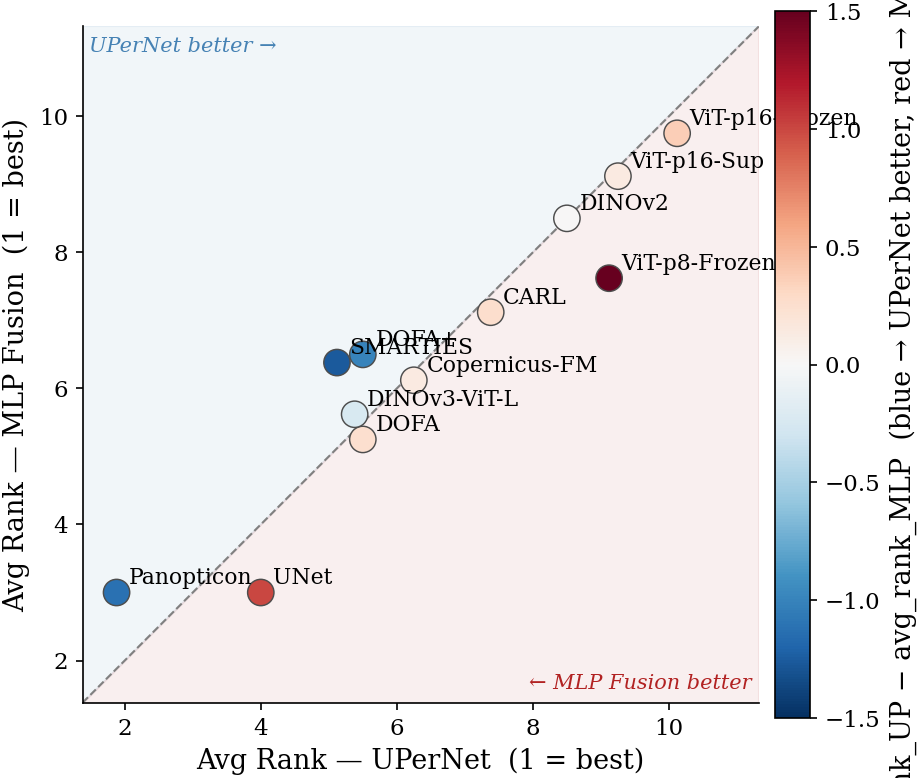

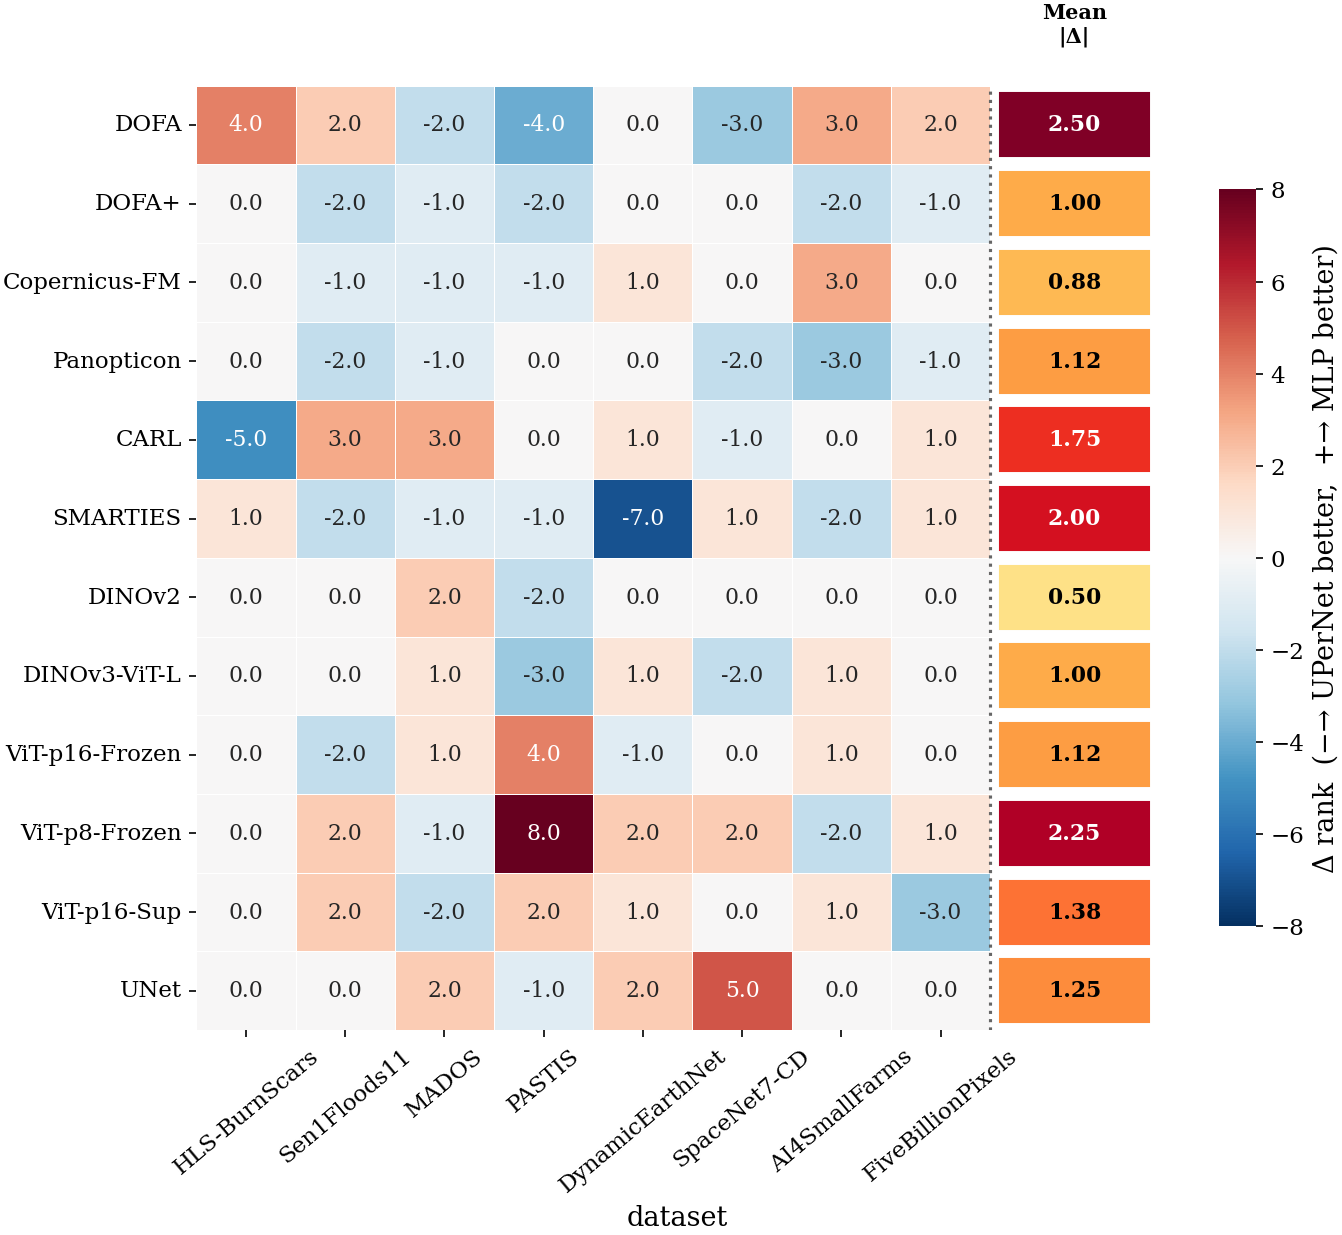

In [15]:
pangaea_ds_order = [DATASET_LABELS[d] for d in DATASET_ORDER]

# Relabeled copies for this section's plots only (see DECODER_CMP_RENAME above).
pivot_upernet_dc = _relabel(pivot_upernet)
pivot_mlp_dc      = _relabel(pivot_mlp)

delta_pangaea, _, _, _ = plot_decoder_sensitivity(
    pivot_upernet_dc, pivot_mlp_dc,
    title="Pangaea Benchmark — Decoder Sensitivity (UPerNet vs MLP Fusion)",
    dataset_order=pangaea_ds_order,
)


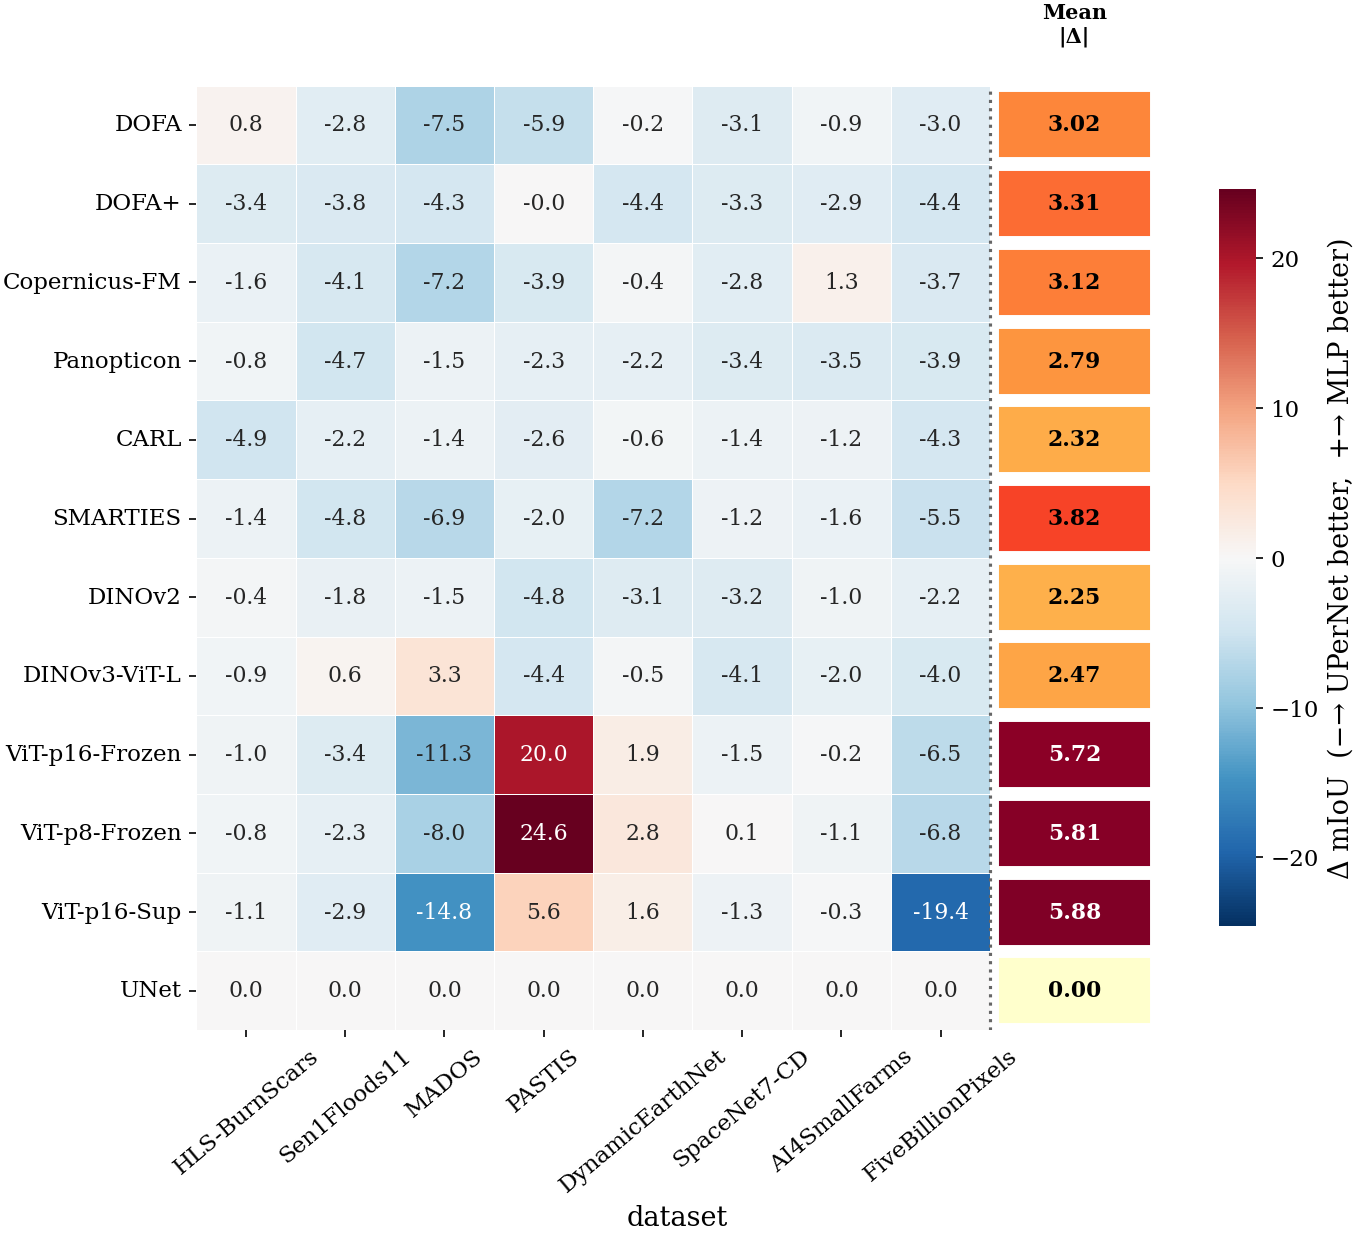

(dataset         HLS-BurnScars  Sen1Floods11  MADOS  PASTIS  DynamicEarthNet  \
 encoder                                                                       
 DOFA                      0.8          -2.8   -7.5    -5.9             -0.2   
 DOFA+                    -3.4          -3.8   -4.3    -0.0             -4.4   
 Copernicus-FM            -1.6          -4.1   -7.2    -3.9             -0.4   
 Panopticon               -0.8          -4.7   -1.5    -2.3             -2.2   
 CARL                     -4.9          -2.2   -1.4    -2.6             -0.6   
 SMARTIES                 -1.4          -4.8   -6.9    -2.0             -7.2   
 DINOv2                   -0.4          -1.8   -1.5    -4.8             -3.1   
 DINOv3-ViT-L             -0.9           0.6    3.3    -4.4             -0.5   
 ViT-p16-Frozen           -1.0          -3.4  -11.3    20.0              1.9   
 ViT-p8-Frozen            -0.8          -2.3   -8.0    24.6              2.8   
 ViT-p16-Sup              -1.1          

In [16]:
plot_miou_delta_heatmap(
    pivot_upernet_dc, pivot_mlp_dc,
    title="Pangaea Benchmark — Decoder Sensitivity (UPerNet vs MLP Fusion)",
    dataset_order=pangaea_ds_order,
)


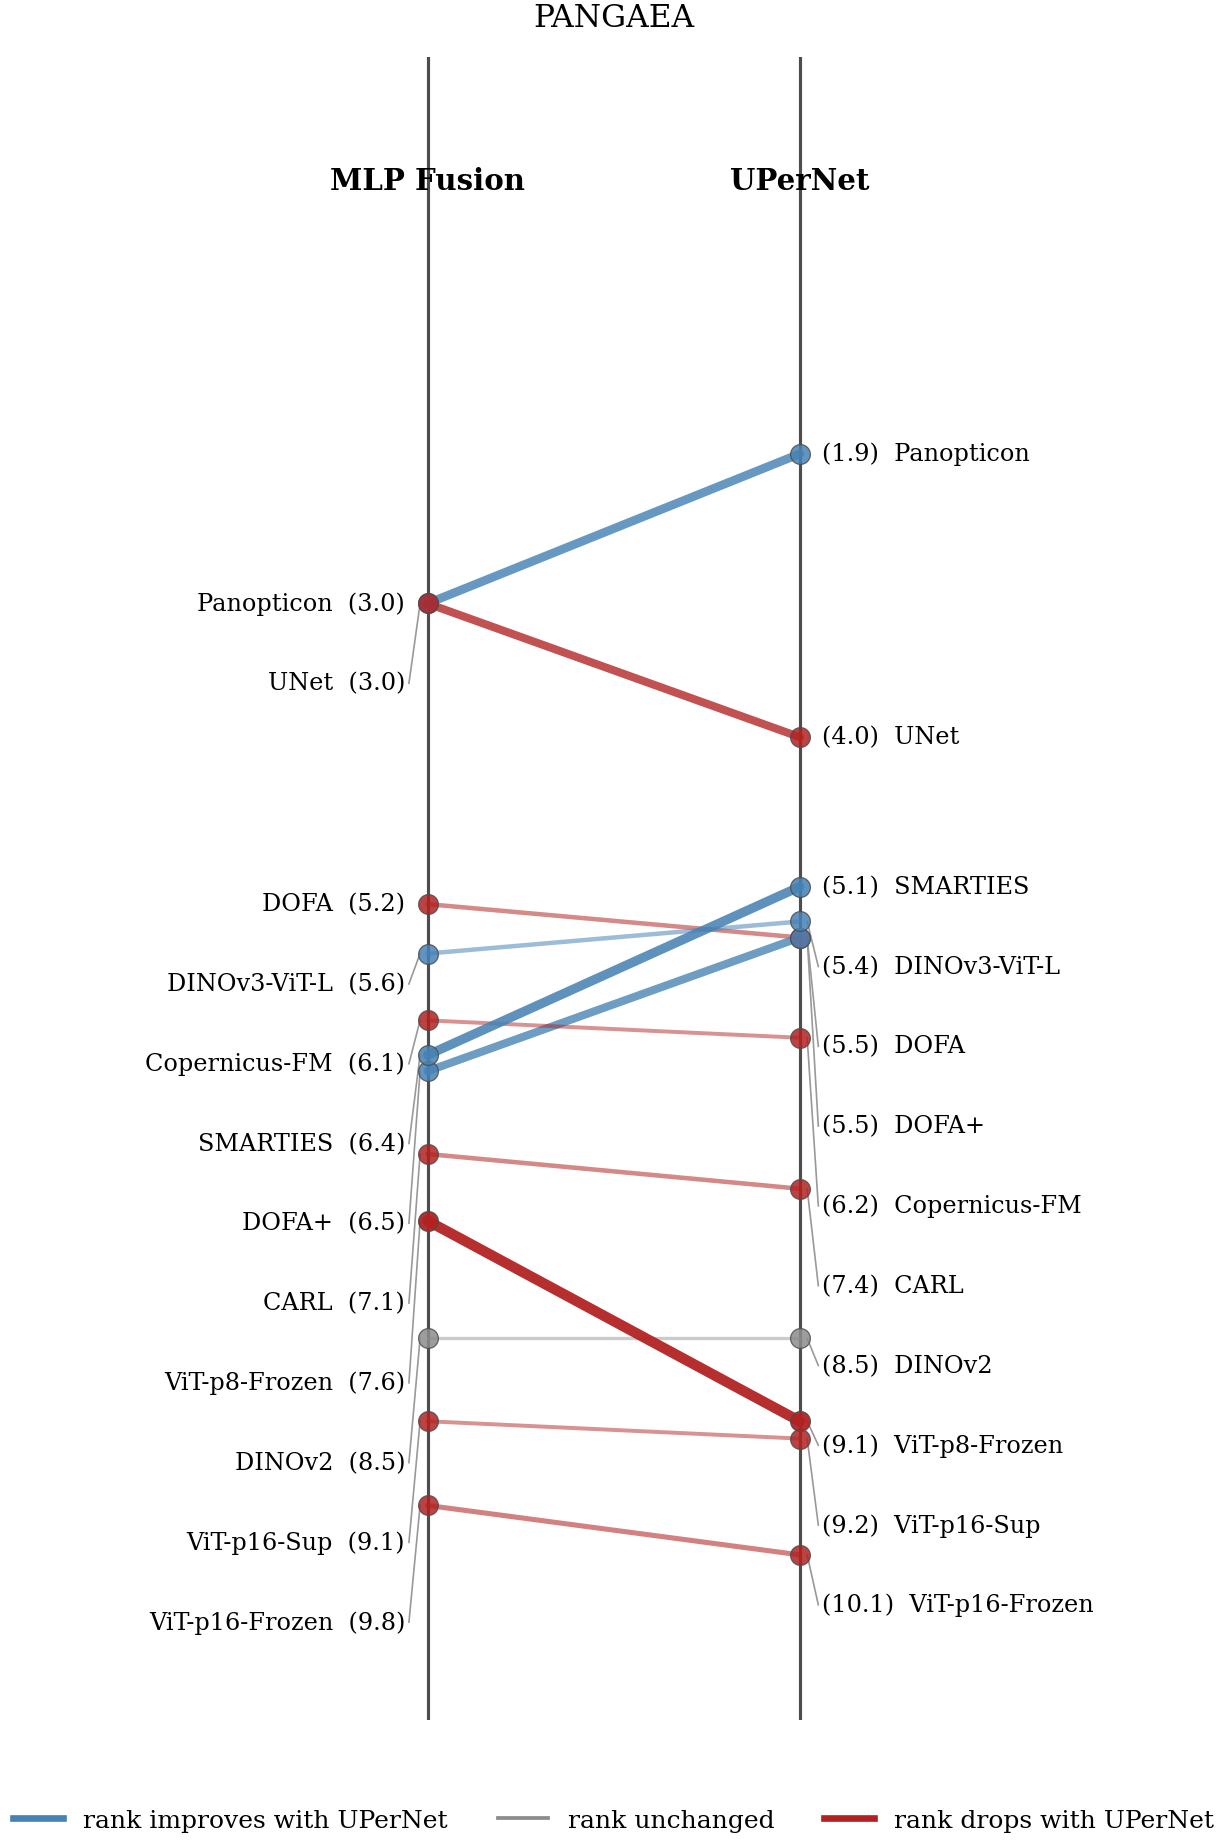

In [17]:
plot_rank_slopegraph(
    pivot_upernet_dc, pivot_mlp_dc,
    title="PANGAEA",
    dataset_order=pangaea_ds_order,
)


### GeoBench

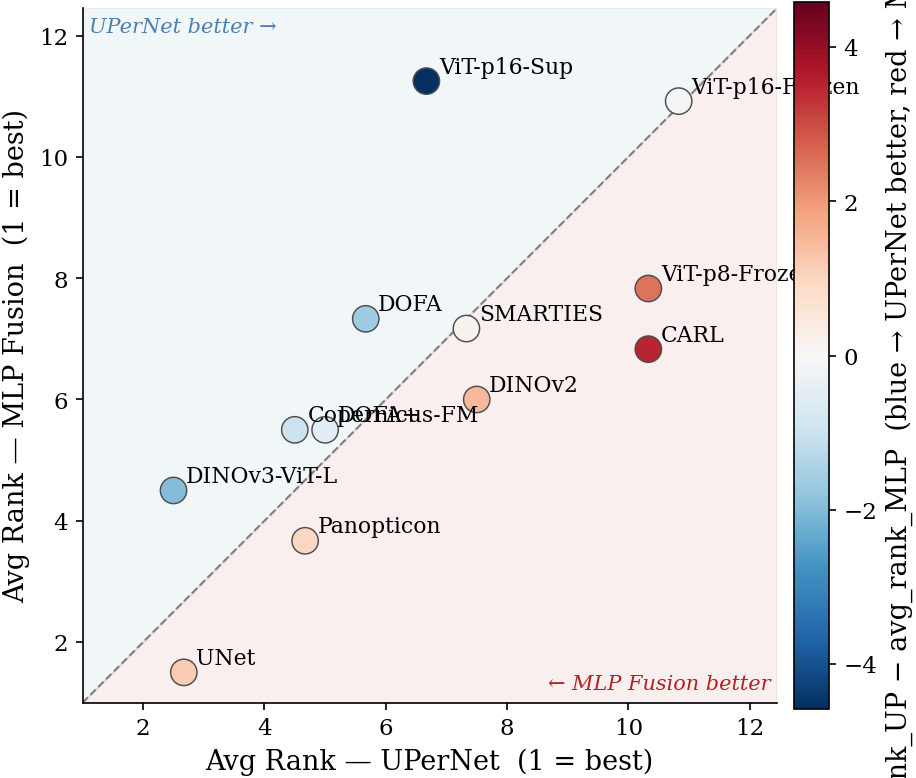

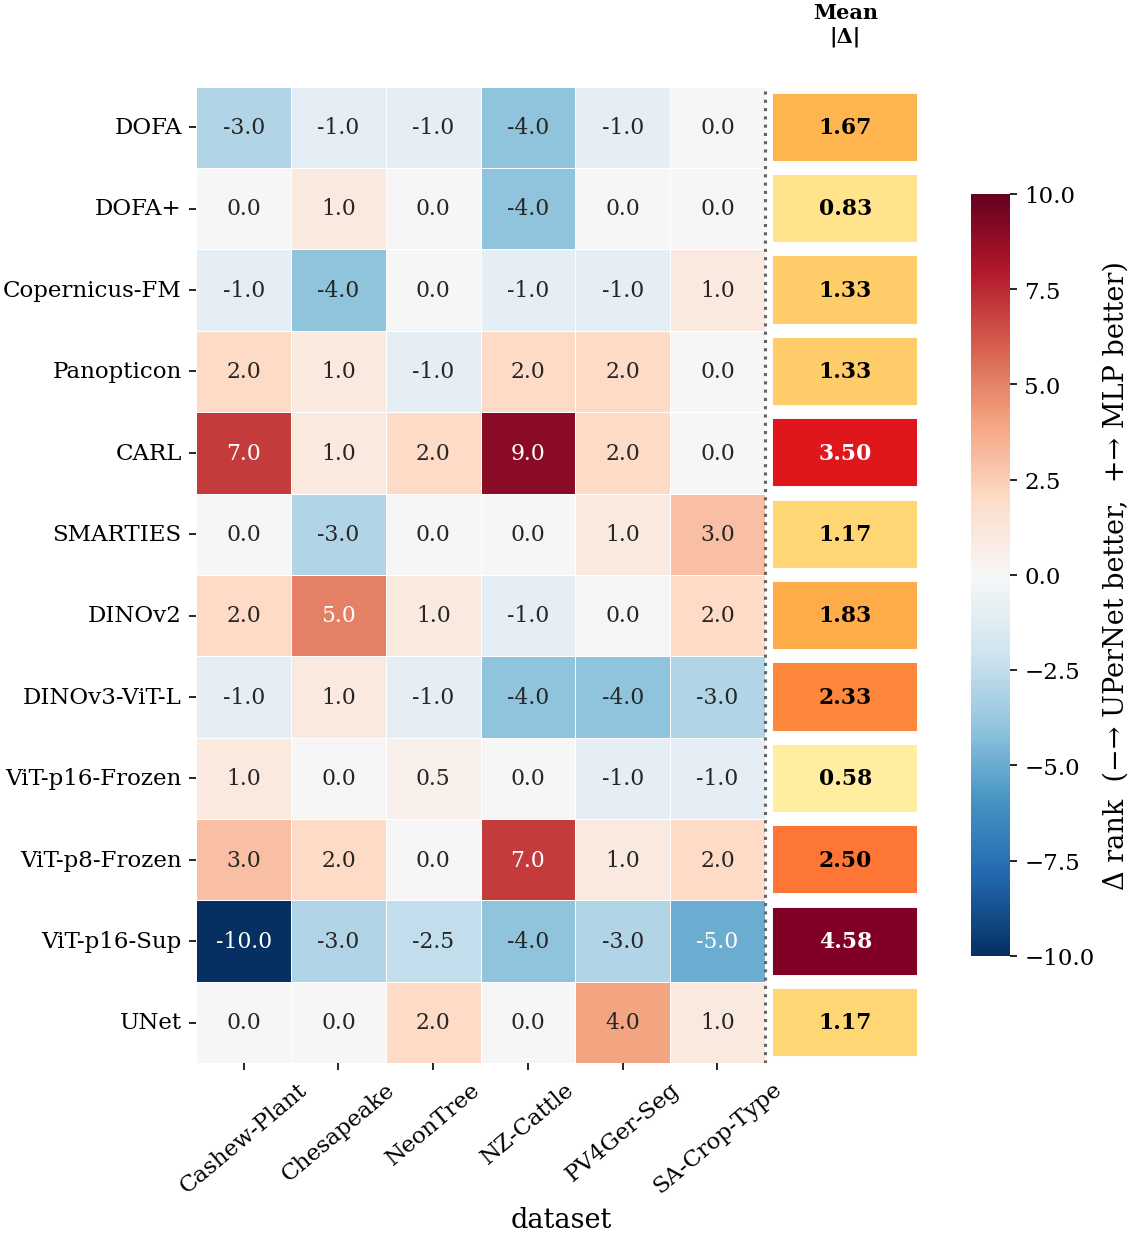

In [18]:
# Relabeled copies for this section's plots only (see DECODER_CMP_RENAME above).
pivot_geo_up_dc  = _relabel(pivot_geo_up)
pivot_geo_mlp_dc = _relabel(pivot_geo_mlp)
geobench_encoder_order_dc = _relabel_order(GEOBENCH_ENCODER_ORDER)

delta_geo, _, _, _ = plot_decoder_sensitivity(
    pivot_geo_up_dc, pivot_geo_mlp_dc,
    title="GeoBench — Decoder Sensitivity (UPerNet vs MLP Fusion)",
    dataset_order=GEOBENCH_DATASET_DISPLAY_ORDER,
    encoder_order=geobench_encoder_order_dc,
)


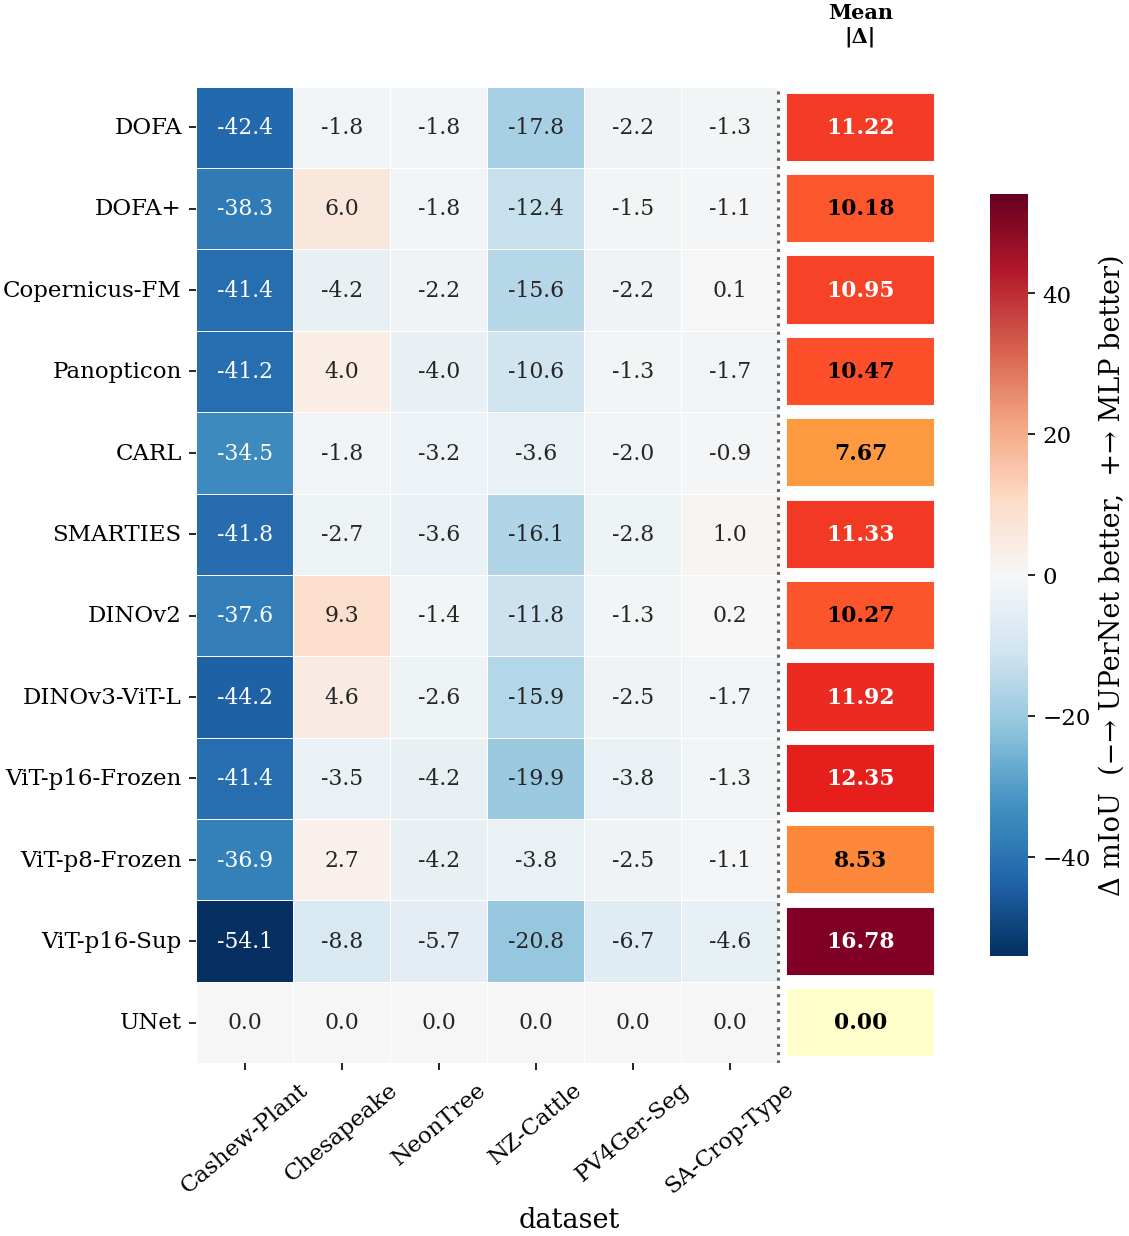

(dataset         Cashew-Plant  Chesapeake  NeonTree  NZ-Cattle  PV4Ger-Seg  \
 encoder                                                                     
 DOFA                   -42.4        -1.8      -1.8      -17.8        -2.2   
 DOFA+                  -38.3         6.0      -1.8      -12.4        -1.5   
 Copernicus-FM          -41.4        -4.2      -2.2      -15.6        -2.2   
 Panopticon             -41.2         4.0      -4.0      -10.6        -1.3   
 CARL                   -34.5        -1.8      -3.2       -3.6        -2.0   
 SMARTIES               -41.8        -2.7      -3.6      -16.1        -2.8   
 DINOv2                 -37.6         9.3      -1.4      -11.8        -1.3   
 DINOv3-ViT-L           -44.2         4.6      -2.6      -15.9        -2.5   
 ViT-p16-Frozen         -41.4        -3.5      -4.2      -19.9        -3.8   
 ViT-p8-Frozen          -36.9         2.7      -4.2       -3.8        -2.5   
 ViT-p16-Sup            -54.1        -8.8      -5.7      -20.8  

In [19]:
plot_miou_delta_heatmap(
    pivot_geo_up_dc, pivot_geo_mlp_dc,
    title="GeoBench — Decoder Sensitivity (UPerNet vs MLP Fusion)",
    dataset_order=GEOBENCH_DATASET_DISPLAY_ORDER,
    encoder_order=geobench_encoder_order_dc,
)


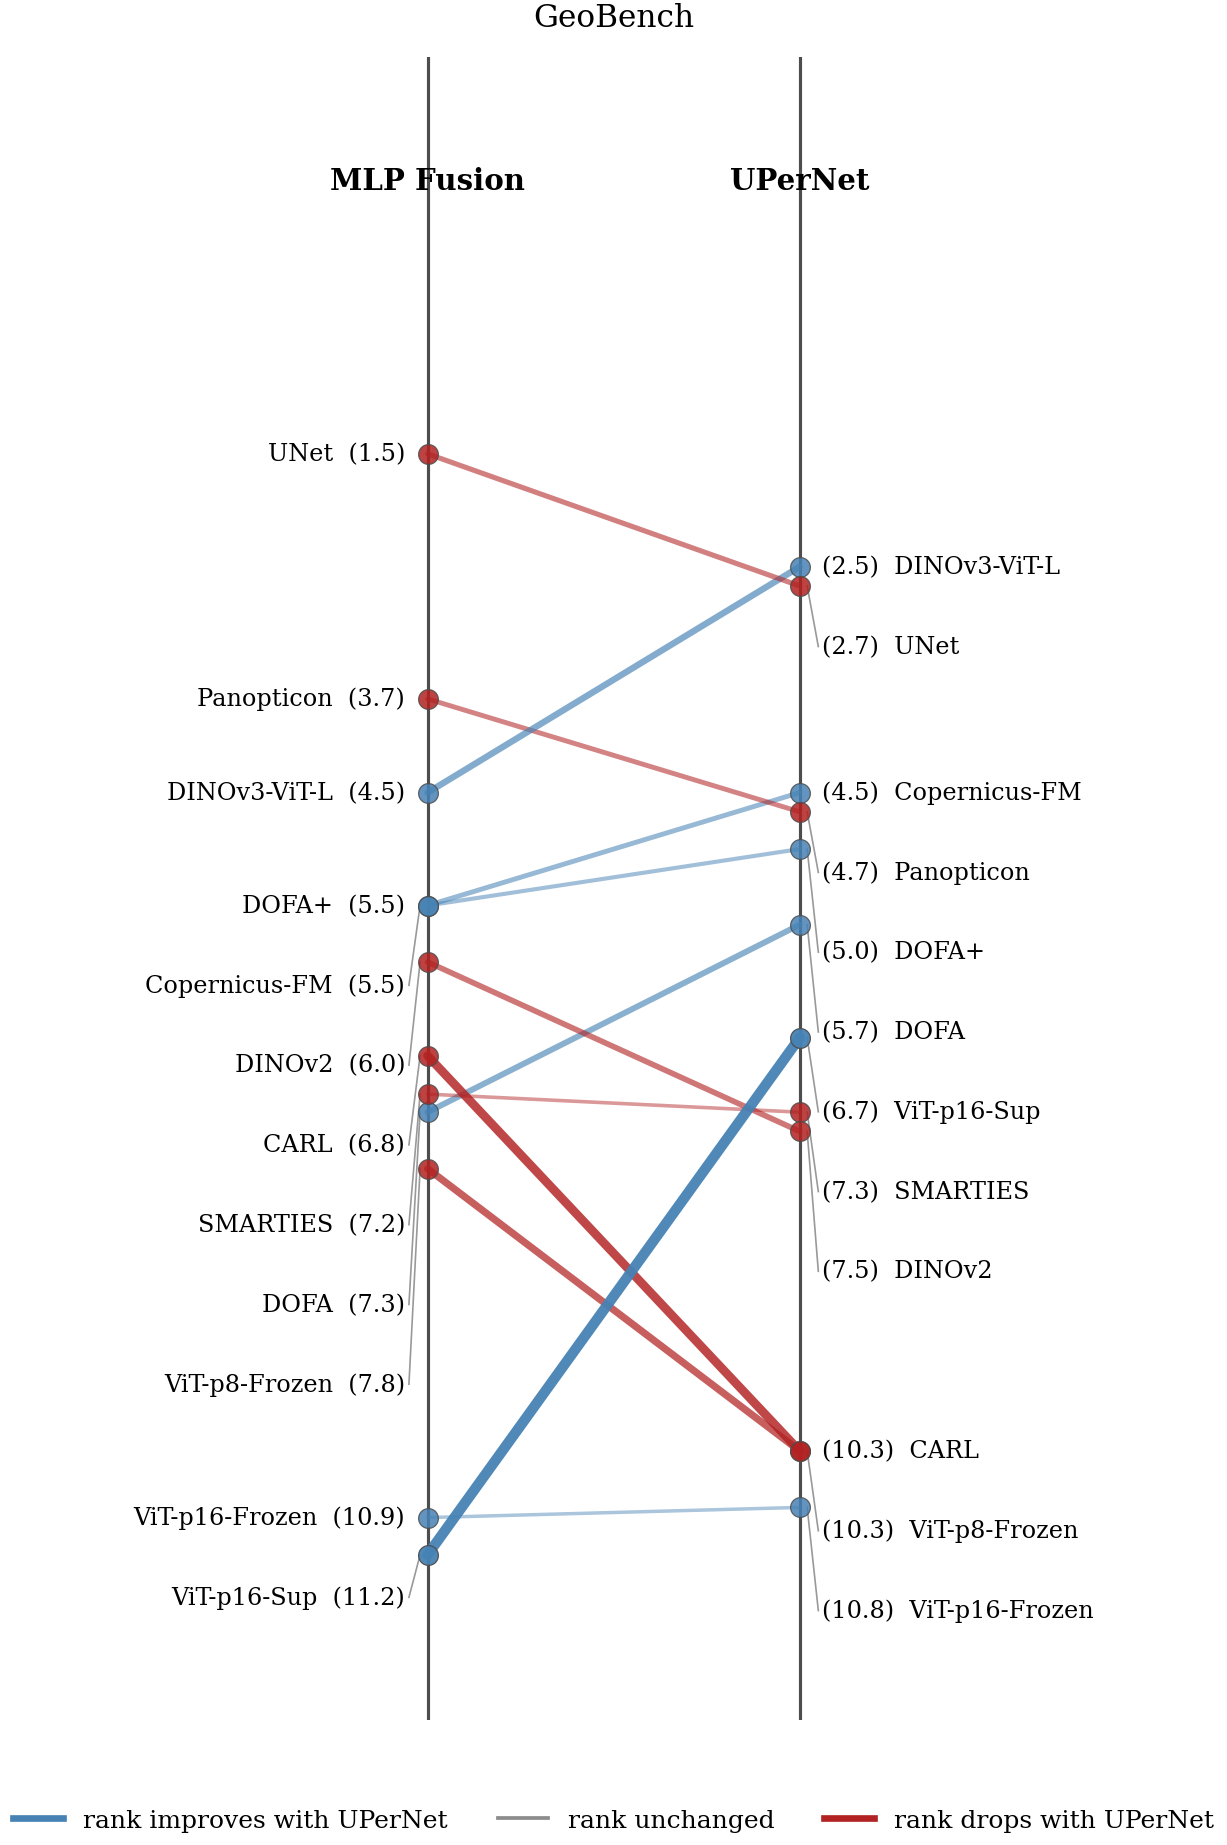

In [20]:
plot_rank_slopegraph(
    pivot_geo_up_dc, pivot_geo_mlp_dc,
    title="GeoBench",
    dataset_order=GEOBENCH_DATASET_DISPLAY_ORDER,
    encoder_order=geobench_encoder_order_dc,
)


## GeoBench Classification results

Linear probe (`cls_linear` decoder, `finetune=False`) on 6 GeoBench classification datasets.

**Primary metric per dataset:**
- **BigEarthNet** (43-class multi-label) → macro **F1-score** (exact-match Accuracy is near zero for multi-label)
- All other datasets (single-label) → **Accuracy**

Results stored in a unified `metric` column so the pivot table is directly comparable.

In [21]:
# ── GeoBench Classification constants ────────────────────────────────────────

GEOBENCH_CLS_DATASET_LABELS = {
    "mbigearthnet": "BigEarthNet",
    "mbrickkiln":   "BrickKiln",
    "meurosat":     "EuroSAT",
    "mforestnet":   "ForestNet",
    "mpv4ger":      "PV4Ger",
    "mso2sat":      "So2Sat",
}
GEOBENCH_CLS_DATASET_ORDER = list(GEOBENCH_CLS_DATASET_LABELS.keys())

GEOBENCH_CLS_DATASET_RE = re.compile(
    r"_(" + "|".join(re.escape(d) for d in GEOBENCH_CLS_DATASET_ORDER) + r")_"
)

# Keyed by experiment subfolder name (same pattern as GeoBench seg)
GEOBENCH_CLS_FOLDER_ENCODER_LABELS = {
    "dofa":               "DOFA",
    "dofav2":             "DOFA+",
    "carl_imagewise":     "CARL",
    "panopticon":         "Panopticon",
    "smarties_vitb":      "SMARTIES",
    "copernicus_fm_base": "Copernicus-FM",
    "dinov2":             "DINOv2",
    "dinov3_vitl":        "DINOv3-ViT-L",
    "vit_scratch":        "ViT-Scratch",
    "vit_frozen_p16":     "ViT-Frozen-p16",
    "vit_frozen_p8":      "ViT-Frozen-p8",
}

# Same relative ordering as PANGAEA_ENCODER_ORDER (no UNet -- no cls variant).
GEOBENCH_CLS_ENCODER_ORDER = [
    "DOFA", "DOFA+", "Copernicus-FM", "Panopticon", "CARL", "SMARTIES",
    "DINOv2", "DINOv3-ViT-L", "ViT-Frozen-p16", "ViT-Frozen-p8", "ViT-Scratch",
]

GEOBENCH_CLS_DATASET_DISPLAY_ORDER = [
    GEOBENCH_CLS_DATASET_LABELS[d] for d in GEOBENCH_CLS_DATASET_ORDER
]


def parse_cls_log_metrics(log_path: Path) -> dict:
    """
    Parse classification train.log-0 for test metrics (Accuracy, F1, Precision, Recall).
    Uses the LAST [test] block if multiple are present.
    """
    if not log_path.exists():
        return {}
    text = log_path.read_text(errors="ignore")
    sections = re.split(r"\[test\] ------- Accuracy", text)
    if len(sections) < 2:
        return {}
    test_block = "[test] ------- Accuracy" + sections[-1]
    metrics = {}
    for section_name, key in [
        ("Accuracy",  "test_Accuracy"),
        ("F1-score",  "test_mF1"),
        ("Precision", "test_Precision"),
        ("Recall",    "test_Recall"),
    ]:
        m = re.search(
            rf"\[test\] ------- {section_name}.*?\[test\] Mean\s+([\d.]+)",
            test_block, re.DOTALL,
        )
        if m:
            metrics[key] = float(m.group(1))
    return metrics


def load_geobench_cls_folder(base_path) -> pd.DataFrame:
    """
    Load GeoBench classification results from base_path/<enc_folder>/<run_dir>/train.log-0.

    Primary metric: Accuracy for single-label tasks; F1-score for mBigEarthNet (multi-label).
    All values stored in a unified 'metric' column.
    """
    rows = []
    for enc_folder in sorted(Path(base_path).iterdir()):
        if not enc_folder.is_dir():
            continue
        enc_label = GEOBENCH_CLS_FOLDER_ENCODER_LABELS.get(enc_folder.name, enc_folder.name)

        for run_dir in sorted(enc_folder.iterdir()):
            if not run_dir.is_dir():
                continue
            m = GEOBENCH_CLS_DATASET_RE.search(run_dir.name)
            if not m:
                continue
            ds_raw = m.group(1)
            log_metrics = parse_cls_log_metrics(run_dir / "train.log-0")
            if not log_metrics:
                continue

            metric_key = "test_mF1" if ds_raw == "mbigearthnet" else "test_Accuracy"
            value = log_metrics.get(metric_key)
            if value is None:
                continue

            rows.append({
                "encoder":     enc_label,
                "dataset":     GEOBENCH_CLS_DATASET_LABELS.get(ds_raw, ds_raw),
                "dataset_raw": ds_raw,
                "metric":      value,
            })
    return pd.DataFrame(rows)


print("GeoBench classification constants and functions defined.")
print("Primary metric: Accuracy (single-label) / F1-score (BigEarthNet multi-label)")

GeoBench classification constants and functions defined.
Primary metric: Accuracy (single-label) / F1-score (BigEarthNet multi-label)


In [22]:
df_geo_cls = load_geobench_cls_folder(
    EXPERIMENTS_BASE / "geobench" / "cls"
)
print(f"{len(df_geo_cls)} runs loaded")

pivot_geo_cls = to_pivot(
    df_geo_cls,
    metric="metric",
    dataset_order=GEOBENCH_CLS_DATASET_DISPLAY_ORDER,
    encoder_order=GEOBENCH_CLS_ENCODER_ORDER,
)
pivot_geo_cls

73 runs loaded


dataset,BigEarthNet,BrickKiln,EuroSAT,ForestNet,PV4Ger,So2Sat,Mean,Avg Rank
encoder,,,,,,,,
DOFA,0.53,0.96,0.89,0.56,0.97,0.58,0.75,4.08
DOFA+,0.51,0.93,0.85,0.50,0.96,0.57,0.72,6.33
Copernicus-FM,0.56,0.95,0.84,0.52,0.97,0.52,0.73,5.67
Panopticon,0.64,0.96,0.94,0.56,0.97,0.63,0.78,2.42
CARL,0.60,0.92,0.39,0.46,0.86,0.47,0.62,8.67
SMARTIES,0.58,0.94,0.90,0.51,0.95,0.53,0.73,5.67
DINOv2,0.56,0.97,0.90,0.47,0.96,0.52,0.73,5.83
DINOv3-ViT-L,0.61,0.98,0.95,0.59,0.95,0.60,0.78,2.67
ViT-Frozen-p16,0.42,0.89,0.78,0.44,0.92,0.42,0.65,10.00
